# What we are going to use  **[Notebook 1]**

- Python
- matplotlib
- The Python standard library
- Jupyter notebooks and nbdev


In [1]:
from pathlib import Path
import pickle, gzip, math, os, time, shutil, matplotlib as mpl, matplotlib.pyplot as plt

# Getting the data

In [2]:
# URL
MNIST_URL = 'https://github.com/mnielsen/neural-networks-and-deep-learning/blob/master/data/mnist.pkl.gz?raw=true'
# Path
data_path = Path('../Data/MNIST')
# mk.dir
data_path.mkdir(exist_ok=True, parents=True)
# mnist path
mnist_path = data_path / 'mnist.pkl.gz'

In [3]:
# use a built in python download tool
from urllib.request import urlretrieve
# downlaod and dont if it exist
if not mnist_path.exists():
    urlretrieve(MNIST_URL, mnist_path)

In [4]:
# take a look
!ls -l ../Data/MNIST

total 16656
-rw-rw-r-- 1 seif seif 17051982 Apr 12 23:47 mnist.pkl.gz


In [5]:
# unzip it and load it to the memory
with gzip.open(mnist_path, 'rb') as f:
    ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding='latin-1')

/tmp/ipykernel_10756/1661484583.py:3: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding='latin-1')


In [6]:
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(50000, 784), dtype=float32)

the type is np array

# Matrix and tensor

## Iterating and islice

In [7]:
x_train[0].shape

(784,)

In [8]:
# make the data sample (image) into list not np array
lst1  =  list(x_train[0])
vals = lst1[200:210]
vals

[np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.19140625),
 np.float32(0.9296875),
 np.float32(0.98828125),
 np.float32(0.98828125),
 np.float32(0.98828125),
 np.float32(0.98828125),
 np.float32(0.98828125)]

In [9]:
# make the smaple as float to see it easier
lst1 = [float(x) for x in lst1]
vals = lst1[200:210]
vals

[0.0,
 0.0,
 0.0,
 0.19140625,
 0.9296875,
 0.98828125,
 0.98828125,
 0.98828125,
 0.98828125,
 0.98828125]

## make the chunks

return vs yield
- return — gives you the whole thing at once, then the function is dead.
- yield — gives you one piece, then pauses the function, remembers where it stopped, and waits for you to ask for the next piece.

In [10]:
def chunks(x,sz):
    for i in range(0, len(x), sz): yield x[i:i+sz]

In [11]:
list(chunks(vals, 5))

[[0.0, 0.0, 0.0, 0.19140625, 0.9296875],
 [0.98828125, 0.98828125, 0.98828125, 0.98828125, 0.98828125]]

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

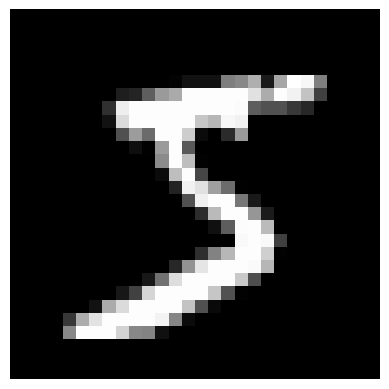

In [12]:
# make a plot
mpl.rcParams['image.cmap'] = 'gray'
plt.imshow(list(chunks(lst1, 28)));
plt.axis('off')

## use the islice from the iter tools

- iter(x)       → stateful pointer into x, remembers position
- islice(it, n) → take next n items, advance pointer

In [13]:
from itertools import islice
it = iter(vals)
islice(it, 5)

The rule: `islice` is lazy. The iterator only moves when something actually consumes the islice object — and list() is what forces that consumption.

In [14]:
list(islice(it, 5))

[0.0, 0.0, 0.0, 0.19140625, 0.9296875]

In [15]:
list(islice(it, 5))

[0.98828125, 0.98828125, 0.98828125, 0.98828125, 0.98828125]

In [16]:
list(islice(it, 5))

[]

    iter(lambda: list(islice(it, 28)), [])
         ↑                              ↑
         call this repeatedly           stop when it returns THIS

     each call → grabs next 28 items from it
     when it is exhausted → islice returns [] → matches sentinel → stops

In [17]:
it = iter(lst1)
img = list(iter(lambda: list(islice(it, 28)), []))

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

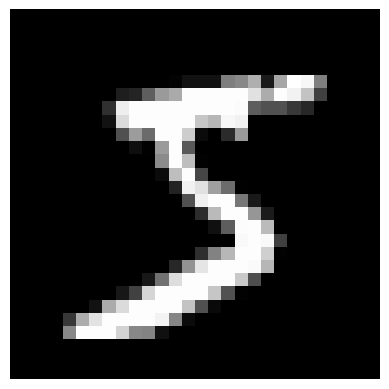

In [18]:
plt.imshow(img)
plt.axis('off')

## indexing

In [19]:
# normal indexing
img[20][15]

0.98828125

`__getitem__` is what Python calls when you use square brackets [] on an object.

In [20]:
# make a matrix
class Matrix:
    def __init__(self,xs):self.xs = xs
    def __getitem__(self, idxs): return self.xs[idxs[0]][idxs[1]]

In [21]:
m = Matrix(img)
m[20, 15]

0.98828125

## use the tensor (we have made the replica already)

`map(function, iterable)` — applies a function to every item in a collection, lazily.

In [22]:
import torch
from torch import tensor
# apply the tensor on the data
x_train,y_train,x_valid,y_valid = map(tensor, (x_train,y_train,x_valid,y_valid))
x_train.shape

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch.Size([50000, 784])

In [23]:
x_train.type()

'torch.FloatTensor'

In [24]:
# make the 28*28 chunks or whatever using the tensor
imgs = x_train.reshape((-1,28,28))  # -1 is the same as 50000
imgs.shape

torch.Size([50000, 28, 28])

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

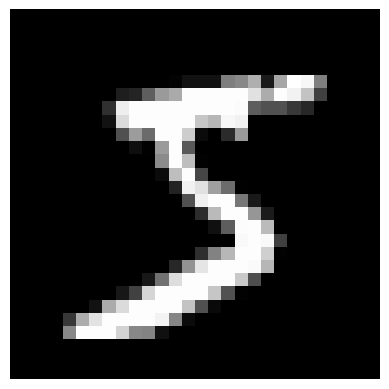

In [25]:
plt.imshow(img)
plt.axis('off')

In [26]:
imgs[0,20,15]

tensor(0.9883)

In [27]:
n, c = x_train.shape
y_train, y_train.shape

(tensor([5, 0, 4,  ..., 8, 4, 8]), torch.Size([50000]))

In [28]:
min(y_train), max(y_train)

(tensor(0), tensor(9))

In [29]:
y_train.min(), y_train.max()

(tensor(0), tensor(9))

# Random numbers

- `seed()`  →  sets the starting rnd_state (3 numbers)
- `rand()`  →  reads rnd_state, does math, saves NEW rnd_state, returns a number

In [30]:
rnd_state = None
def seed(a):
    global rnd_state   # global makes it use the global variable and not make a local one , so it can update the outer one
    a, x = divmod(a, 30268)
    a, y = divmod(a, 30306)
    a, z = divmod(a, 30322)
    rnd_state = int(x) + 1, int(y) + 1, int(z) + 1

In [31]:
seed(457428938475)
rnd_state

(4976, 20238, 499)

In [32]:
def rand():
    global rnd_state
    x, y, z = rnd_state
    x = (171 * x) % 30269
    y = (172 * y) % 30307
    z = (170 * z) % 30323
    rnd_state = x, y, z
    return (x / 30269 + y / 30307 + z / 30323) % 1.0

In [33]:
rand(), rand(), rand()

(0.7645251082582081, 0.7920889799553945, 0.06912886811267205)

- `os.fork()`
splits process into parent (returns `True`) and child (returns `False`), both share identical state

In [34]:
if os.fork():
    print(f'In parent: {rand()}')
else:
    print(f'In child: {rand()}')
    os._exit(os.EX_OK)

In parent: 0.9559050644103264


/tmp/ipykernel_10756/1846057469.py:1: DeprecationWarning: This process (pid=10756) is multi-threaded, use of fork() may lead to deadlocks in the child.
  if os.fork():


In child: 0.9559050644103264


In [35]:
if os.fork():
    print(f'In parent: {torch.rand(1)}')
else:
    print(f'In child: {torch.rand(1)}')
    os._exit(os.EX_OK)

In parent: tensor([0.2821])


/tmp/ipykernel_10756/3061111610.py:1: DeprecationWarning: This process (pid=10756) is multi-threaded, use of fork() may lead to deadlocks in the child.
  if os.fork():


In child: tensor([0.2821])


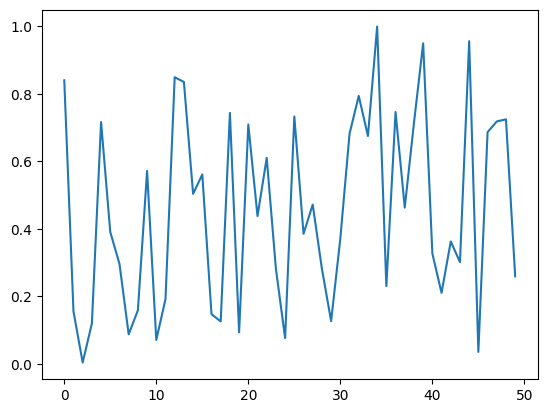

In [36]:
plt.plot([rand() for _ in range(50)]);

different in small scale

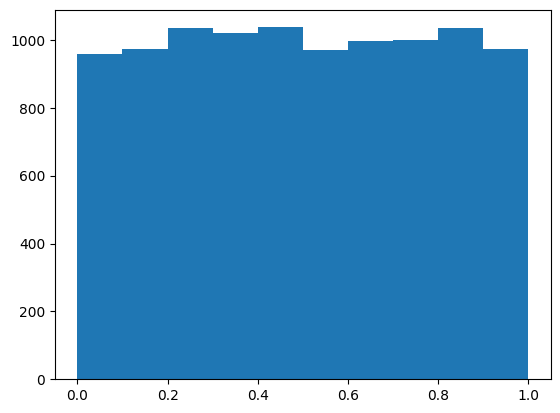

In [37]:
plt.hist([rand() for _ in range(10000)]);

uniform on big scale

In [38]:
%timeit -n 10 list(chunks([rand() for _ in range(7840)], 10))

2.03 ms ± 42.9 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [39]:
%timeit -n 10 torch.randn(784,10)

The slowest run took 5.28 times longer than the fastest. This could mean that an intermediate result is being cached.
44.2 μs ± 39.4 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


the torch method is much faster

# Matrix multiplication

In [40]:
# make weights & bias
weights =  torch.rand(784,10)   # 10 classes
bias  = torch.rand(10)

In [41]:
x_valid.shape

torch.Size([10000, 784])

In [42]:
# lets take 5 images for experiments as matrix 1 (m1)
m1 = x_valid[:5]
m2 = weights

In [43]:
m1.shape,m2.shape

(torch.Size([5, 784]), torch.Size([784, 10]))

In [44]:
ar,ac = m1.shape # n_rows * n_cols
br,bc = m2.shape
(ar,ac),(br,bc)

((5, 784), (784, 10))

In [45]:
# that is the result tensor for the @ for m1 and m2
t1 = torch.zeros(ar, bc)
t1.shape

torch.Size([5, 10])

In [46]:
# make the MM
for i in range(ar):         # 5
    for j in range(bc):     # 10
        for k in range(ac): # 784
            t1[i,j] += m1[i,k] * m2[k,j]

t1

tensor([[43.8722, 47.4909, 42.8102, 43.6035, 44.5321, 39.9376, 40.5683, 45.5394,
         43.4785, 43.6869],
        [45.4310, 44.8895, 44.6893, 46.1515, 48.9888, 44.7883, 40.7808, 44.4767,
         45.7829, 44.4098],
        [45.7724, 42.8891, 35.9852, 39.9678, 41.0141, 40.8339, 41.7313, 43.4412,
         37.2909, 41.2189],
        [44.6323, 40.6386, 34.3118, 40.2769, 40.6970, 36.6926, 41.3446, 42.8511,
         35.6171, 40.0286],
        [54.4573, 52.8566, 50.4833, 49.9782, 51.1027, 51.7412, 49.8151, 55.5983,
         45.9529, 50.8797]])

In [47]:
t1.shape

torch.Size([5, 10])

In [48]:
# make it easier to read
torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
t1

tensor([[43.87, 47.49, 42.81, 43.60, 44.53, 39.94, 40.57, 45.54, 43.48, 43.69],
        [45.43, 44.89, 44.69, 46.15, 48.99, 44.79, 40.78, 44.48, 45.78, 44.41],
        [45.77, 42.89, 35.99, 39.97, 41.01, 40.83, 41.73, 43.44, 37.29, 41.22],
        [44.63, 40.64, 34.31, 40.28, 40.70, 36.69, 41.34, 42.85, 35.62, 40.03],
        [54.46, 52.86, 50.48, 49.98, 51.10, 51.74, 49.82, 55.60, 45.95, 50.88]])

In [49]:
# make the arrays also easier to read
import numpy as np
np.set_printoptions(precision=2, linewidth=140)

In [50]:
# functionizing what we did
def matmul(a,b):
    (ar,ac),(br,bc) = a.shape,b.shape
    c = torch.zeros(ar, bc)
    for i in range(ar):
        for j in range(bc):
            for k in range(ac):
                c[i,j] += a[i,k] * b[k,j]
    return c

In [51]:
# Time taken?
%time _=matmul(m1, m2)

CPU times: user 389 ms, sys: 1.22 ms, total: 390 ms
Wall time: 389 ms


In [52]:
# number operations?
ar*bc*ac

39200

# Numba
**(python library that does compile in computer code)[Faster]**

In [53]:
from numba import njit

In [54]:
@njit
# make a dot product function because the MM is multiple dot_products  --> in last loop in MM function
def dot(a,b):
    res = 0.
    for i in range(len(a)): res+=a[i]*b[i]
    return res

In [55]:
from numpy import array

In [56]:
# look at time (before numba compile it)
%time dot(array([1.,2,3]),array([2.,3,4]))

CPU times: user 1.53 s, sys: 56.4 ms, total: 1.58 s
Wall time: 517 ms


20.0

In [57]:
# look at time (after numba compile it)
%time dot(array([1.,2,3]),array([2.,3,4]))

CPU times: user 22 μs, sys: 3 μs, total: 25 μs
Wall time: 30.5 μs


20.0

In [58]:
# update the MM funciton
def matmul(a,b):
    (ar,ac),(br,bc) = a.shape,b.shape
    c = torch.zeros(ar, bc)
    for i in range(ar):
        for j in range(bc): c[i,j] = dot(a[i,:], b[:,j])
    return c

In [59]:
# make np array for numba
m1a,m2a = m1.numpy(),m2.numpy()

In [60]:
from fastcore.test import *

In [61]:
test_close(t1,matmul(m1a, m2a),eps=1e-3)  # eps=1e-3 --->  less strict comparison

In [62]:
# look at the time taken
%timeit -n 50 matmul(m1a,m2a)

212 μs ± 5.03 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


# Element operations

In [63]:
a = tensor([10., 6, -4])
b = tensor([2., 8, 7])
a,b

(tensor([10.,  6., -4.]), tensor([2., 8., 7.]))

In [64]:
a + b

tensor([12., 14.,  3.])

In [65]:
(a < b)

tensor([False,  True,  True])

In [66]:
(a < b).float().mean()

tensor(0.67)

In [67]:
# dot product
a * b , (a * b).sum()

(tensor([ 20.,  48., -28.]), tensor(40.))

In [68]:
# pytorch version
torch.dot(a,b)

tensor(40.)

In [69]:
# implement both and see the time
## MANUAL
def matmul(a,b):
    (ar,ac),(br,bc) = a.shape,b.shape
    c = torch.zeros(ar, bc)
    for i in range(ar):
        for j in range(bc): c[i,j] = (a[i,:] * b[:,j]).sum()
    return c

In [70]:
test_close(t1,matmul(m1, m2),eps=1e-3)

In [71]:
%timeit -n 50 _=matmul(m1, m2)

576 μs ± 17.4 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


In [72]:
## TORCH.DOT
def matmul(a,b):
    (ar,ac),(br,bc) = a.shape,b.shape
    c = torch.zeros(ar, bc)
    for i in range(ar):
        for j in range(bc): c[i,j] = torch.dot(a[i,:], b[:,j])
    return c

In [73]:
test_close(t1,matmul(m1, m2),eps=1e-3)

In [74]:
%timeit -n 50 _=matmul(m1, m2)

465 μs ± 23.5 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


# BroadCasting

## BroadCasting

In [75]:
a

tensor([10.,  6., -4.])

In [76]:
a > 0 # 0 is being broadcast to have the same dimensions as a.

tensor([ True,  True, False])

In [77]:
a + 1

tensor([11.,  7., -3.])

In [78]:
m = tensor([[1., 2., 3.],
            [4., 5., 6.],
            [7., 8., 9.]])

In [79]:
2 * m

tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.],
        [14., 16., 18.]])

In [80]:
c = tensor([10.,20,30]); c

tensor([10., 20., 30.])

In [81]:
m.shape,c.shape

(torch.Size([3, 3]), torch.Size([3]))

In [82]:
m + c

tensor([[11., 22., 33.],
        [14., 25., 36.],
        [17., 28., 39.]])

In [83]:
t = c.expand_as(m)
t

tensor([[10., 20., 30.],
        [10., 20., 30.],
        [10., 20., 30.]])

We don't really copy the rows, but it looks as if we did. In fact, the rows are given a *stride* of 0.

In [84]:
# see what the expanded (t) is in memory
t.storage()

/tmp/ipykernel_10756/4152841491.py:2: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  t.storage()


 10.0
 20.0
 30.0
[torch.storage.TypedStorage(dtype=torch.float32, device=cpu) of size 3]

In [85]:
# here is the stride
t.stride(), t.shape

((0, 1), torch.Size([3, 3]))

    # normal 3x3 tensor
    t = torch.tensor([[1,2,3],
                      [4,5,6],
                      [7,8,9]])
    t.stride()  # → (3, 1)
    # move to next row    → jump 3 elements
    # move to next column → jump 1 element

    # YOUR tensor → stride (0, 1)
    # move to next row    → jump 0 elements  ← STAY IN SAME PLACE
    # move to next column → jump 1 element

## Adding dimensions

In [86]:
c.unsqueeze(0), c[None, :] , c[None]

(tensor([[10., 20., 30.]]),
 tensor([[10., 20., 30.]]),
 tensor([[10., 20., 30.]]))

In [87]:
c.unsqueeze(1), c[:, None]

(tensor([[10.],
         [20.],
         [30.]]),
 tensor([[10.],
         [20.],
         [30.]]))

In [88]:
c.shape, c.unsqueeze(0).shape , c.unsqueeze(1).shape

(torch.Size([3]), torch.Size([1, 3]), torch.Size([3, 1]))

You can always skip trailling ':'s. And '...' means '*all preceding dimensions*'

In [89]:
c[None].shape,c[...,None].shape

(torch.Size([1, 3]), torch.Size([3, 1]))

## Broadcasting Rules

In [90]:
c[None,:]

tensor([[10., 20., 30.]])

In [91]:
c[None,:].shape

torch.Size([1, 3])

In [92]:
c[:,None]

tensor([[10.],
        [20.],
        [30.]])

In [93]:
c[:,None].shape

torch.Size([3, 1])

In [94]:
# both expand to 3*3
c[None,:] * c[:,None]

tensor([[100., 200., 300.],
        [200., 400., 600.],
        [300., 600., 900.]])

In [95]:
# both expand to 3*3
c[None] > c[:,None]

tensor([[False,  True,  True],
        [False, False,  True],
        [False, False, False]])

In [96]:
m*m

tensor([[ 1.,  4.,  9.],
        [16., 25., 36.],
        [49., 64., 81.]])

# MM with BroadCasting

## MM with BroadCasting

In [97]:
digit = m1[0] # this was the 5 example images
digit.shape,m2.shape

(torch.Size([784]), torch.Size([784, 10]))

In [98]:
digit[:,None].shape

torch.Size([784, 1])

In [99]:
digit[:,None].expand_as(m2) # --> expand_as() is done automatically

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [100]:
(digit[:,None]*m2).shape

torch.Size([784, 10])

In [101]:
# update the funciton
def matmul(a,b):
    (ar,ac),(br,bc) = a.shape,b.shape
    c = torch.zeros(ar, bc)
    for i in range(ar):
#       c[i,j] = (a[i,:] * b[:,j]).sum()      # previous version
        c[i]   = (a[i,:,None] * b).sum(dim=0) # broadcast version
    return c

In [102]:
test_close(t1,matmul(m1, m2),eps=1e-3)

In [103]:
%timeit -n 50 _=matmul(m1, m2)

73 μs ± 11.8 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


## Make this on the whole dataset

Our time has gone from ~500ms to <0.1ms, an over 5000x improvement! We can run on the whole dataset now.

In [104]:
tr = matmul(x_train, weights)
tr

tensor([[56.01, 54.40, 47.50,  ..., 56.38, 51.81, 54.01],
        [59.61, 61.71, 55.01,  ..., 64.96, 59.70, 63.74],
        [38.31, 38.93, 36.94,  ..., 38.85, 35.47, 41.59],
        ...,
        [44.79, 47.63, 46.32,  ..., 50.12, 43.54, 44.88],
        [45.74, 43.68, 40.14,  ..., 47.20, 42.31, 47.06],
        [52.31, 52.47, 48.76,  ..., 55.71, 53.09, 52.04]])

In [105]:
tr.shape

torch.Size([50000, 10])

In [106]:
%time _=matmul(x_train, weights)

CPU times: user 664 ms, sys: 922 μs, total: 665 ms
Wall time: 630 ms


# Einstein summation

In [107]:
x = torch.tensor([[1,1,1],
                 [2,2,2]])
y = torch.tensor([[5],
                 [10],
                 [15]])

mr = torch.einsum('ik,kj->ikj', x, y)
mr , mr.shape

(tensor([[[ 5],
          [10],
          [15]],
 
         [[10],
          [20],
          [30]]]),
 torch.Size([2, 3, 1]))

In [108]:
# here it is making * and not summing
mr = torch.einsum('ik,kj->ikj', m1, m2)
mr.shape

torch.Size([5, 784, 10])

In [109]:
# make a sum
mr.sum(1).shape

torch.Size([5, 10])

In [110]:
# here it makes the summision ---> MM [@]
mr = torch.einsum('ik,kj->ij', m1, m2)
mr.shape

torch.Size([5, 10])

In [111]:
def matmul(a,b): return torch.einsum('ik,kj->ij', a, b)

In [112]:
test_close(tr, matmul(x_train, weights), eps=1e-3)

In [113]:
%timeit -n 5 _=matmul(x_train, weights)

28 ms ± 1.62 ms per loop (mean ± std. dev. of 7 runs, 5 loops each)


# Pytocrch opertation

In [114]:
test_close(tr, x_train@weights, eps=1e-3)

In [115]:
%timeit -n 5 _=torch.matmul(x_train, weights)

29.1 ms ± 1.31 ms per loop (mean ± std. dev. of 7 runs, 5 loops each)


almost the same speed

# CUDA

## Make a fake CUDA function in python

In [116]:
# we are going to make a loop for the i,j in later functions

def matmul(grid,a,b,c):
    i,j = grid
    # make a safety to make sure that if the grid is bigger than the output(c) we leave the extra spaces unasigned by any value so that the computer knows that it is empty and so that the cimputer doesnt put garbage values there --> avoid crashing
    if i < c.shape[0] and j < c.shape[1]:  # REMEMBER :we don't make = because indexing is from 0
        tmp = 0.
        for k in range(a.shape[1]): tmp += a[i,k] * b[k,j]
        # assign the value to the output
        c[i,j] = tmp

In [117]:
m1.shape , m2.shape

(torch.Size([5, 784]), torch.Size([784, 10]))

In [118]:
res = torch.zeros(ar, bc)
matmul((0,0), m1, m2, res)
res

tensor([[43.87,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00],
        [ 0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00],
        [ 0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00],
        [ 0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00],
        [ 0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00,  0.00]])

- ***args**   = "I don't know how many **unnamed arguments** you'll pass, just forward them all"
- ****kwargs** = "I don't know how many **named arguments** you'll pass, just forward them all"

In [119]:
def launch_kernel(kernel, grid_x, grid_y, *args, **kwargs):
    for i in range(grid_x):
        for j in range(grid_y): kernel((i,j), *args, **kwargs)

In [120]:
res = torch.zeros(ar, bc)
launch_kernel(matmul, ar, bc, m1, m2, res)
res

tensor([[43.87, 47.49, 42.81, 43.60, 44.53, 39.94, 40.57, 45.54, 43.48, 43.69],
        [45.43, 44.89, 44.69, 46.15, 48.99, 44.79, 40.78, 44.48, 45.78, 44.41],
        [45.77, 42.89, 35.99, 39.97, 41.01, 40.83, 41.73, 43.44, 37.29, 41.22],
        [44.63, 40.64, 34.31, 40.28, 40.70, 36.69, 41.34, 42.85, 35.62, 40.03],
        [54.46, 52.86, 50.48, 49.98, 51.10, 51.74, 49.82, 55.60, 45.95, 50.88]])

## Make the real cuda version using numba

In [121]:
from numba import cuda

@cuda.jit
def matmul(a,b,c):
    i, j = cuda.grid(2)   # cuda makes grid for us with dimension arg --> (2 dim)
    if i < c.shape[0] and j < c.shape[1]:
        tmp = 0.
        for k in range(a.shape[1]): tmp += a[i, k] * b[k, j]
        c[i,j] = tmp

In [122]:
# transfer data to the gpu
r = np.zeros(tr.shape)
m1g,m2g,rg = map(cuda.to_device, (x_train,weights,r))

In [123]:
r.shape

(50000, 10)

In [124]:
TPB = 16
rr,rc = r.shape
blockspergrid = (math.ceil(rr / TPB), math.ceil(rc / TPB))
blockspergrid

(3125, 1)

In [125]:
matmul[blockspergrid, (TPB,TPB)](m1g,m2g,rg)
r = rg.copy_to_host()
test_close(tr, r, eps=1e-3)

In [126]:
%%timeit -n 10
matmul[blockspergrid, (TPB,TPB)](m1g,m2g,rg)   # using our MM
r = rg.copy_to_host()

8.98 ms ± 631 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [127]:
m1c,m2c = x_train.cuda(),weights.cuda()

In [128]:
r=(m1c@m2c).cpu()

In [129]:
%timeit -n 10 r=(m1c@m2c).cpu()    # using the torch MM

1.06 ms ± 58.4 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


- **cuda.to_device()**  → numba's way   (works with numpy arrays)
- **.cuda()**           → PyTorch's way (works with tensors)

Our broadcasting version was >500ms, and our CUDA version is around 0.5ms, which is another 1000x improvement compared to broadcasting. So our total speedup is around 5 million times!

# Clustering **[Notebook 2]**

In [130]:
# imports
import math, matplotlib.pyplot as plt, operator, torch
from functools import partial

In [131]:
torch.manual_seed(42)
torch.set_printoptions(precision=3, linewidth=140, sci_mode=False)

# Create data

In [132]:
n_clusters = 6
n_samples = 250  # samples per cluster

In [133]:
centroids = torch.rand(n_clusters, 2) * 70 - 35
# shape (6, 2) → 6 points, each with x and y coordinate
# torch.rand gives values 0→1
# ×70 scales to 0→70
# -35 shifts to -35→35
# so 6 random center points scattered in a -35 to 35 grid
centroids.shape

torch.Size([6, 2])

In [134]:
from torch.distributions.multivariate_normal import MultivariateNormal
from torch import tensor
def sample(m):
    return MultivariateNormal(m, torch.diag(tensor([5.,5.]))).sample((n_samples,))
# m = one centroid point (the center of the blob)
# MultivariateNormal = a 2D gaussian bell curve centered at m
# torch.diag([5,5]) = spread/width of the blob (5 units in x, 5 in y)
# .sample((250,)) = generate 250 random points around that center
# returns shape (250, 2)

In [135]:
slices = [sample(c) for c in centroids]
slices[0].shape

torch.Size([250, 2])

In [136]:
data = torch.cat(slices) # glue them together
data.shape

torch.Size([1500, 2])

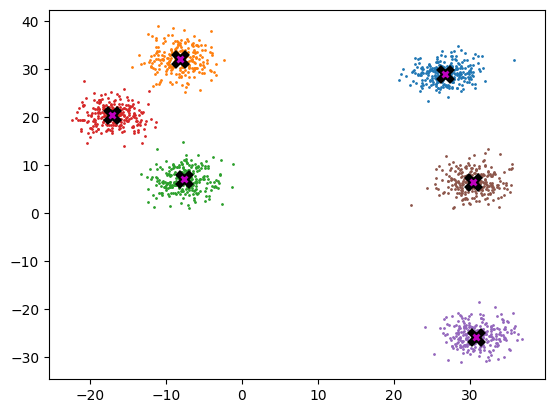

In [137]:
# make a plotting function
def plot_data(centroids, data, n_samples, ax=None):
    if ax is None: _,ax = plt.subplots()
    for i, centroid in enumerate(centroids):
        samples = data[i*n_samples:(i+1)*n_samples]
        ax.scatter(samples[:,0], samples[:,1], s=1)
        ax.plot(*centroid, markersize=10, marker="x", color='k', mew=5)
        ax.plot(*centroid, markersize=5, marker="x", color='m', mew=2)

plot_data(centroids, data, n_samples)

# Mean Shift

The algorithm is as follows:
* For each data point x in the sample X, find the distance between that point x and every other point in X
* Create weights for each point in X by using the **Gaussian kernel** of that point's distance to x
    * This weighting approach penalizes points further away from x
    * The rate at which the weights fall to zero is determined by the **bandwidth**, which is the standard deviation of the Gaussian
* Update x as the weighted average of all other points in X, weighted based on the previous step

This will iteratively push points that are close together even closer until they are next to each other.

In [138]:
data.shape

torch.Size([1500, 2])

In [139]:
midp = data.mean(0)
midp

tensor([ 9.222, 11.604])

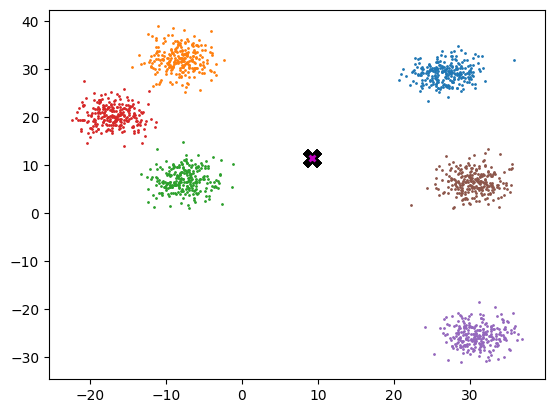

In [140]:
plot_data([midp]*6, data, n_samples)

In [141]:
# Make the formula
def gaussian(d, bw): return torch.exp(-0.5*((d/bw))**2) / (bw*math.sqrt(2*math.pi))

- d  = distance from a point to others
- bw = bandwidth → controls how wide the bell curve is (how far influence reaches)

In [142]:
def plot_func(f):
    # generates 100 evenly spaced numbers between 0 and 10.
    x = torch.linspace(0,10,100)
    plt.plot(x, f(x))

One easy way to choose bandwidth is to find which bandwidth covers one third of the data. (N_clusters)

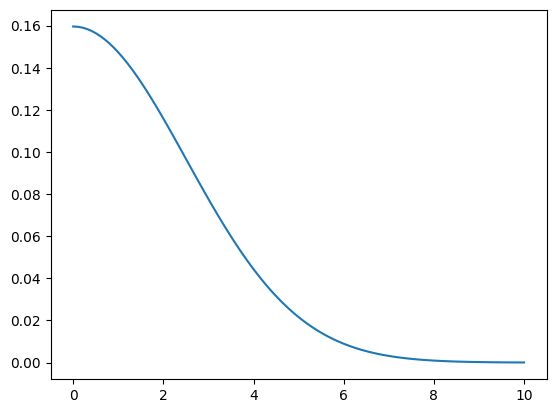

In [143]:
plot_func(partial(gaussian, bw=2.5))

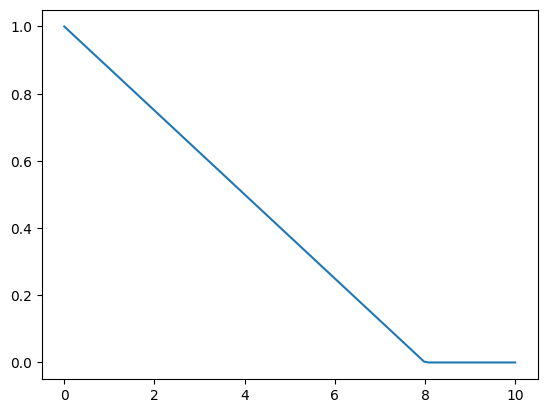

In [144]:
# we are going to also try another function
def tri(d, i): return (-d + i).clamp_min(0) / i

plot_func(partial(tri, i=8))

In [145]:
# clone the data
ps = data.clone()
p = ps[0]
p

tensor([26.204, 26.349])

In [146]:
p.shape , ps.shape

(torch.Size([2]), torch.Size([1500, 2]))

In [147]:
# finding the distance from one point to all of the other points
dist = ((ps-p)**2).sum(1).sqrt()
dist[0:10]

tensor([0.000, 3.899, 4.834, 3.726, 6.273, 4.122, 6.560, 6.002, 3.488, 5.129])

In [148]:
# an einsum version
ein_dist = torch.einsum('ij->i',(ps-p)**2).sqrt()
ein_dist[0:10]

tensor([0.000, 3.899, 4.834, 3.726, 6.273, 4.122, 6.560, 6.002, 3.488, 5.129])

In [149]:
# Make the weights
weight = gaussian(dist,2.5)
weight

tensor([    0.160,     0.047,     0.025,  ...,     0.000,     0.000,     0.000])

In [150]:
weight.shape,ps.shape

(torch.Size([1500]), torch.Size([1500, 2]))

In [151]:
# Multiply the weights with the points
weight[...,None]*ps

tensor([[    4.182,     4.205],
        [    1.215,     1.429],
        [    0.749,     0.706],
        ...,
        [    0.000,     0.000],
        [    0.000,     0.000],
        [    0.000,     0.000]])

In [152]:
(weight[...,None]*ps).sum(0)

tensor([406.866, 431.454])

In [153]:
weight.sum()

tensor(15.388)

In [154]:
# make a one update function
def one_update(ps):
    for i,p in enumerate(ps):
        dist =  ((ps-p)**2).sum(1).sqrt()
        weight = gaussian(dist, 2.5)
        # OR: weight = tri(dist, 8)
        ps[i] = ((weight[...,None]*ps).sum(0))/(weight.sum()) # the /(weight.sum()) is a key for normalizing the numbers and making it represent real point on the graph

In [155]:
def meanshift(data):
    ps = data.clone()
    for it in range(5): one_update(ps)
    return ps

In [156]:
%time ps=meanshift(data)

CPU times: user 530 ms, sys: 2.64 ms, total: 533 ms
Wall time: 530 ms


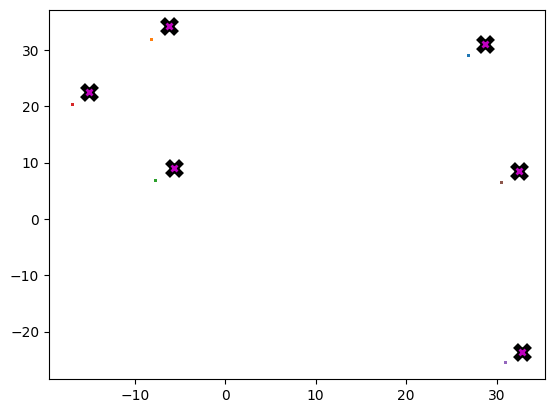

In [157]:
plot_data(centroids+2, # just to see where the data have settled
          ps, n_samples)

# Make animaiton

In [158]:
# Imports
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [159]:
# make a one plot funciton
def one_plot(d):  # (d) is the frame number it is for the FuncAnimation fn down there
    if d: one_update(ps)
    ax.clear()  # is to make the picture clear for the next frame not stacked on the top of each other
    plot_data(centroids+2,ps, n_samples, ax=ax)

In [160]:
ps = data.clone()
fig,ax = plt.subplots()
ani = FuncAnimation(fig, one_plot, frames=5, interval=1000, repeat=False)
plt.close()
HTML(ani.to_jshtml())

- **ani.to_jshtml()**   # just returns a giant ugly string, doesn't display anything
- **HTML(ani.to_jshtml())**   # Jupyter renders it as a working video player in the cell


# GPU Batched algorithm

- to acc the algo

In [161]:
ps = data.clone()
bs = 5
bp = ps[:bs]
bp.shape

torch.Size([5, 2])

In [162]:
# to be able to get the distance , matrix wise we need to make ps-ps
ps[None].shape , bp[...,None,:].shape , (ps[None]-bp[...,None,:]).shape

(torch.Size([1, 1500, 2]), torch.Size([5, 1, 2]), torch.Size([5, 1500, 2]))

In [163]:
# make a function
def dist_gpu(a,b): return (((a[...,None,:]-b[None])**2).sum(2)).sqrt()

In [164]:
dist_gpu(bp,ps).shape

torch.Size([5, 1500])

In [165]:
weight = gaussian(dist_gpu(bp, ps), 2)
weight

tensor([[    0.199,     0.030,     0.011,  ...,     0.000,     0.000,     0.000],
        [    0.030,     0.199,     0.009,  ...,     0.000,     0.000,     0.000],
        [    0.011,     0.009,     0.199,  ...,     0.000,     0.000,     0.000],
        [    0.035,     0.199,     0.009,  ...,     0.000,     0.000,     0.000],
        [    0.001,     0.004,     0.144,  ...,     0.000,     0.000,     0.000]])

In [166]:
weight.shape,ps.shape

(torch.Size([5, 1500]), torch.Size([1500, 2]))

In [167]:
weight[...,None].shape,ps[None].shape

(torch.Size([5, 1500, 1]), torch.Size([1, 1500, 2]))

In [168]:
# multi
(weight[...,None]*ps[None]).shape

torch.Size([5, 1500, 2])

In [169]:
# sum
((weight[...,None]*ps[None]).sum(1)).shape

torch.Size([5, 2])

In [170]:
# that is the same as MM
(weight@ps).shape

torch.Size([5, 2])

In [171]:
# the deniminator of the meanshift equation
summ_weights = weight.sum(1, keepdim=True)
summ_weights.shape

torch.Size([5, 1])

In [172]:
# that is all of the equation
(weight@ps)/summ_weights

tensor([[26.376, 27.692],
        [26.101, 29.643],
        [28.892, 28.990],
        [26.071, 29.559],
        [29.323, 29.685]])

In [173]:
# make fn that replicates what we have did
def mean_shift_gpu(data, bs=500, epochs=5):
    n = len(data)
    ps = data.clone()
    for epoch in range(epochs):
        for i in range (0,n,bs):
            s = slice(i,min(i+bs,n)) # that just makes the indicies
            weight = gaussian(dist_gpu(ps[s], ps), 2.5)
            weight_sum = weight.sum(1, keepdim=True)
            ps[s] = (weight@ps)/weight_sum
    return ps

In [174]:
# Data --> gpu
data = data.cuda()

In [175]:
# works?
ps = meanshift(data).cpu()

In [176]:
%timeit -n 5 _=mean_shift_gpu(data, 1250).cpu()

2.31 ms ± 905 μs per loop (mean ± std. dev. of 7 runs, 5 loops each)


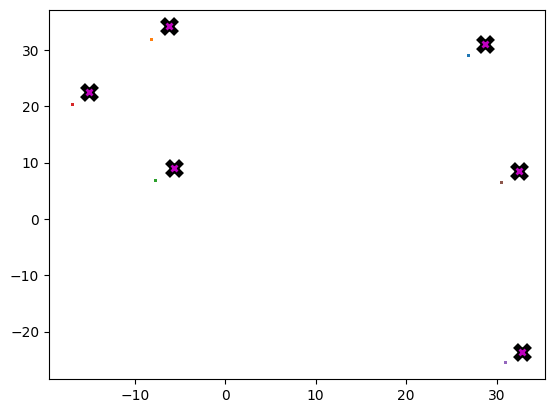

In [177]:
plot_data(centroids+2,ps, n_samples)

- make the mean drft better
- make a new algortithm + anmimate it
- filer spectrums

# Making NN from scratch **[Notebook 3]**

In [178]:
# add some default setting
mpl.rcParams['image.cmap'] = 'gray'
torch.set_printoptions(precision=2, linewidth=125, sci_mode=False)
np.set_printoptions(precision=2, linewidth=125)

In [179]:
# make the data to tensor
x_train, y_train, x_valid, y_valid = map(tensor, [x_train, y_train, x_valid, y_valid])

/tmp/ipykernel_10756/2998560482.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_train, y_train, x_valid, y_valid = map(tensor, [x_train, y_train, x_valid, y_valid])


In [180]:
x_train.shape

torch.Size([50000, 784])

# Make a basic version

## Model

In [181]:
n,m = x_train.shape
c = y_train.max()+1  # this is the output --> 10
n,m,c

(50000, 784, tensor(10))

In [182]:
# num hidden
nh = 50

In [183]:
w1 = torch.randn(m,nh)
b1 = torch.zeros(nh)
w2 = torch.randn(nh,1)  # we are making for this initial version the output as 1 because we use the MSE for now not the CrossEntropy
b2 = torch.zeros(1)

In [184]:
# make a linear layer
def linear(x,w,b): return x@w+b

In [185]:
# lets try it
t = linear(x_valid,w1,b1)
t.shape

torch.Size([10000, 50])

In [186]:
def relu(x): return x.clamp_min(0.)

In [187]:
t = relu(t)
t.shape

torch.Size([10000, 50])

In [188]:
# make a model
def model(x):
    t = linear(x,w1,b1)
    t = relu(t)
    return linear(t,w2,b2)

In [189]:
preds = model(x_valid)
preds.shape

torch.Size([10000, 1])

## MSE

In [190]:
preds.shape , y_valid.shape

(torch.Size([10000, 1]), torch.Size([10000]))

In [191]:
(preds.squeeze(-1)-y_valid).shape

torch.Size([10000])

In [192]:
def mse(preds,y): return (preds.squeeze(-1)-y).pow(2).mean()
# MSE make -> (all +ve , amplify loss effect and big errors, later in derivative,  etc)

In [193]:
mse(preds,y_valid)

tensor(3333.20)

## Gradient and Backpropgation

In [194]:
def linear_grad_calc(x,y,w,b):
    w.g = x.t()@y.g
    x.g = y.g @ w.t() # we are just calculating this so that we can continue the backpropagation and get the gradient of the weights before that, so that later we can update them
    b.g = y.g.sum(0)

In [195]:
def forward_backward(x,y):
    ## Forward
    l1 = linear(x,w1,b1)
    r1 = relu(l1)
    out = linear(r1,w2,b2)
    diff = out.squeeze()-y
    loss = diff.pow(2).mean()
    ## Backward
    out.g = 2.*(diff).unsqueeze(-1) / x.shape[0]
    linear_grad_calc(r1,out,w2,b2)
    l1.g = (l1>0).float() * r1.g  # (l1>0).float() --> this makes a musk for weights that became 0 in relu, so we make their gradient 0 because their weights didnt make any change
    linear_grad_calc(x,l1,w1,b1)

In [196]:
forward_backward(x_train, y_train)

In [197]:
# Save for testing against later
def get_grad(x): return x.g.clone()

chks = w1,w2,b1,b2,x_train
grads = w1g,w2g,b1g,b2g,ig = tuple(map(get_grad, chks))

We cheat a little bit and use PyTorch autograd to check our results.

In [198]:
def mkgrad(x): return x.clone().requires_grad_(True)
ptgrads = w12,w22,b12,b22,xt2 = tuple(map(mkgrad, chks))

In [199]:
def forward(inp, targ):
    l1 = linear(inp, w12, b12)
    l2 = relu(l1)
    out = linear(l2, w22, b22)
    return mse(out, targ)

In [200]:
loss = forward(xt2, y_train)
loss.backward()

In [201]:
for a,b in zip(grads, ptgrads): test_close(a, b.grad, eps=0.01)

# Making classes version

In [202]:
class Relu():
    def __call__(self,x):
        self.x = x
        self.y =  x.clamp_min(0.)
        return self.y
    def backward(self): self.x.g = (self.x>0).float() * self.y.g

In [203]:
class Lin():
    def __init__(self, w, b): self.w,self.b = w,b
    def __call__(self,x):
        self.x = x
        self.y = linear(x,self.w,self.b)
        return self.y
    def backward(self):
        self.x.g = self.y.g @ self.w.t()
        self.w.g = self.x.t() @ self.y.g
        self.b.g = self.y.g.sum(0)

In [204]:
class Mse():
    def __call__(self,x,y):
        self.x,self.y = x,y
        self.out = mse(x,y)
        return self.out
    def backward(self):
        self.x.g = 2. * ((self.x.squeeze()-self.y).unsqueeze(-1)) / self.y.shape[0]

In [205]:
class Model():
    def __init__(self,w1,b1,w2,b2):
        self.layers = [Lin(w1,b1), Relu(), Lin(w2,b2)]
        self.loss = Mse()
    def __call__(self,x,y):
        for l in self.layers: x = l(x)
        return self.loss(x,y)
    def backward(self):
        self.loss.backward()
        for l in reversed(self.layers): l.backward()

In Backpropagation:
- MSE writes into its self.x.g → that is the second linear layer’s self.y.g
- Second linear uses its self.y.g to compute its self.x.g → that is the ReLU’s self.y.g
- ReLU uses its self.y.g to compute its self.x.g → that is the first linear’s self.y.g
- First linear uses its self.y.g to compute its self.x.g → that goes back to the original input.

All because every self.y of one layer is literally the same Python object as the self.x of the next layer. That’s the entire “autograd” trick in this minimalist implementation.

In [206]:
model = Model(w1,b1,w2,b2)

In [207]:
loss = model(x_train, y_train)

In [208]:
model.backward()

In [209]:
test_close(w2g, w2.g, eps=0.01)
test_close(b2g, b2.g, eps=0.01)
test_close(w1g, w1.g, eps=0.01)
test_close(b1g, b1.g, eps=0.01)
test_close(ig, x_train.g, eps=0.01)

# Make a module

In [210]:
class Module():
    def __call__(self, *args):
        self.args = args
        self.y = self.forward(*args)
        return self.y

    def forward(self): raise Exception('not implemented')
    def backward(self): self.bwd(self.y, *self.args)
    def bwd(self): raise Exception('not implemented')

In [211]:
class Relu(Module):
    def forward(self, x): return x.clamp_min(0.)
    def bwd(self, y, x): x.g = (x>0).float() * y.g

In [212]:
class Lin(Module):
    def __init__(self, w, b): self.w,self.b = w,b
    def forward(self, x): return x@self.w + self.b
    def bwd(self, y, x):
        x.g = self.y.g @ self.w.t()
        self.w.g = x.t() @ self.y.g
        self.b.g = self.y.g.sum(0)

In [213]:
class Mse(Module):
    def forward (self, x, y): return (x.squeeze() - y).pow(2).mean()
    def bwd(self, _, x, y): x.g = 2*(x.squeeze()-y).unsqueeze(-1) / y.shape[0] # the _ is because bwd take (self.y, *self.args)

In [214]:
model = Model(w1, b1, w2, b2)

In [215]:
loss = model(x_train, y_train)

In [216]:
model.backward()

In [217]:
test_close(w2g, w2.g, eps=0.01)
test_close(b2g, b2.g, eps=0.01)
test_close(w1g, w1.g, eps=0.01)
test_close(b1g, b1.g, eps=0.01)
test_close(ig, x_train.g, eps=0.01)

# Autograd

In [218]:
# imports
from torch import nn
import torch.nn.functional as F

In [219]:
class Linear(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.w = torch.randn(n_in,n_out).requires_grad_()
        self.b = torch.zeros(n_out).requires_grad_()
    def forward(self, inp): return inp@self.w + self.b

In [220]:
class Model(nn.Module):
    def __init__(self, n_in, nh, n_out):
        super().__init__()
        self.layers = [Linear(n_in,nh), nn.ReLU(), Linear(nh,n_out)]

    def __call__(self, x, targ):
        for l in self.layers: x = l(x)
        return F.mse_loss(x, targ[:,None])

In [221]:
model = Model(m, nh, 1)
loss = model(x_train, y_train.float())
loss.backward()

In [222]:
l0 = model.layers[0]
l0.b.grad

tensor([  48.53,  -35.89,   61.22,    3.26,   18.38,   42.67,   55.20, -138.33,  -25.03,   30.33,  -19.82,  -38.62,   -3.01,
          91.35,  157.55,  -13.83,  -77.01, -113.88,  -17.76,    1.89,   23.50,  113.57,    1.19,   45.91,    1.15,  106.06,
         -44.56,  226.46,    3.65,  -18.18,  -76.35,   -1.15,   30.96,  -93.96, -129.65,    7.38, -129.39,  -30.02,   51.68,
           1.43,   67.95,   66.36,    6.51,   21.57,   -1.59,  181.90,   -4.00,  288.08,  -52.18,   23.59])

# Mini Batch training **[Notebook 4]**

In [223]:
#| default_exp training

In [224]:
#|export
import pickle,gzip,math,os,time,shutil,torch,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from pathlib import Path
from torch import tensor,nn
import torch.nn.functional as F

In [225]:
class Model(nn.Module):
    def __init__(self, n_in, nh, n_out):
        super().__init__()
        self.layers = [nn.Linear(n_in,nh), nn.ReLU(), nn.Linear(nh,n_out)]

    def __call__(self, x):
        for l in self.layers: x = l(x)
        return x

In [226]:
n,m = x_train.shape
c = y_train.max()+1
nh = 50

In [227]:
model = Model(m,nh,c.item())
preds = model(x_train)
preds.shape

torch.Size([50000, 10])

# Cross entropy loss
First, we will need to compute the softmax of our activations. This is defined by:

$$\hbox{softmax(x)}_{i} = \frac{e^{x_{i}}}{e^{x_{0}} + e^{x_{1}} + \cdots + e^{x_{n-1}}}$$

or more concisely:

$$\hbox{softmax(x)}_{i} = \frac{e^{x_{i}}}{\sum\limits_{0 \leq j \lt n} e^{x_{j}}}$$

In practice, we will need the log of the softmax when we calculate the loss.

In [228]:
def softmax(x): return (x.exp()/(x.exp().sum(-1,keepdim=True)))
softmax(preds)

tensor([[0.09, 0.10, 0.10,  ..., 0.10, 0.11, 0.11],
        [0.09, 0.10, 0.10,  ..., 0.09, 0.11, 0.11],
        [0.10, 0.12, 0.10,  ..., 0.09, 0.11, 0.10],
        ...,
        [0.10, 0.10, 0.10,  ..., 0.10, 0.11, 0.10],
        [0.10, 0.10, 0.10,  ..., 0.10, 0.11, 0.10],
        [0.10, 0.11, 0.10,  ..., 0.10, 0.11, 0.10]], grad_fn=<DivBackward0>)

In [229]:
def log_softmax(x): return (x.exp()/(x.exp().sum(-1,keepdim=True))).log()

why take the log:

if model is very confident and correct:
- probability = 0.99 → loss = -log(0.99) = 0.01  ← tiny loss, good

if model is wrong:
- probability = 0.01 → loss = -log(0.01) = 4.6   ← huge loss, bad

- any log() between 0,1 will give **(-ve)**

In [230]:
log_softmax(preds)

tensor([[-2.39, -2.27, -2.28,  ..., -2.32, -2.21, -2.22],
        [-2.41, -2.34, -2.28,  ..., -2.37, -2.22, -2.18],
        [-2.32, -2.16, -2.27,  ..., -2.39, -2.21, -2.32],
        ...,
        [-2.35, -2.27, -2.31,  ..., -2.30, -2.20, -2.32],
        [-2.30, -2.26, -2.34,  ..., -2.30, -2.24, -2.33],
        [-2.30, -2.25, -2.35,  ..., -2.34, -2.18, -2.27]], grad_fn=<LogBackward0>)

$$\log \left ( \frac{a}{b} \right ) = \log(a) - \log(b)$$

In [231]:
# simplifying using the log properties
def log_softmax(x): return x - x.exp().sum(-1,keepdim=True).log()

Then, there is a way to compute the log of the sum of exponentials in a more stable way, called the [LogSumExp trick](https://en.wikipedia.org/wiki/LogSumExp). The idea is to use the following formula:

$$\log \left ( \sum_{j=1}^{n} e^{x_{j}} \right ) = \log \left ( e^{a} \sum_{j=1}^{n} e^{x_{j}-a} \right ) = a + \log \left ( \sum_{j=1}^{n} e^{x_{j}-a} \right )$$

where a is the maximum of the $x_{j}$.

In [232]:
def logsumexp(x):
    a = x.max(-1)[0]
    return a + (x-a[:,None]).exp().sum(-1).log()

In [233]:
def log_softmax(x): return x - x.logsumexp(-1,keepdim=True)

In [234]:
test_close(logsumexp(preds), preds.logsumexp(-1)) # the second one is the pytorch one
sm_log_preds = log_softmax(preds)
sm_log_preds

tensor([[-2.39, -2.27, -2.28,  ..., -2.32, -2.21, -2.22],
        [-2.41, -2.34, -2.28,  ..., -2.37, -2.22, -2.18],
        [-2.32, -2.16, -2.27,  ..., -2.39, -2.21, -2.32],
        ...,
        [-2.35, -2.27, -2.31,  ..., -2.30, -2.20, -2.32],
        [-2.30, -2.26, -2.34,  ..., -2.30, -2.24, -2.33],
        [-2.30, -2.25, -2.35,  ..., -2.34, -2.18, -2.27]], grad_fn=<SubBackward0>)

In [235]:
y_valid

tensor([3, 8, 6,  ..., 5, 6, 8])

In [236]:
# nll is the same as the CrossEntropy loss
def nll(x,y): return -x[range(y.shape[0]) , y].mean()

In [237]:
loss = nll(sm_log_preds, y_train)
loss

tensor(2.31, grad_fn=<NegBackward0>)

In [238]:
test_close(F.nll_loss(F.log_softmax(preds, -1), y_train), loss, 1e-3)

In [239]:
test_close(F.cross_entropy(preds, y_train), loss, 1e-3)

# Make a training loop

In [240]:
# make the loss function
loss_func = F.cross_entropy

In [241]:
bs = 50  # batch size
xb = x_train[0:bs]  # one batch
preds = model(xb)
preds.shape,preds[0]

(torch.Size([50, 10]),
 tensor([-0.09,  0.02,  0.02,  0.01,  0.12, -0.08, -0.23, -0.02,  0.08,  0.07], grad_fn=<SelectBackward0>))

In [242]:
yb = y_train[0:bs]
yb.shape , yb

(torch.Size([50]),
 tensor([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9, 4, 0, 9, 1, 1, 2, 4, 3, 2, 7, 3, 8, 6, 9, 0, 5, 6, 0, 7,
         6, 1, 8, 7, 9, 3, 9, 8, 5, 9, 3]))

In [243]:
loss_func(preds,yb)

tensor(2.31, grad_fn=<NllLossBackward0>)

In [244]:
preds.argmax(dim=1)

tensor([4, 9, 1, 3, 3, 4, 3, 8, 3, 8, 4, 3, 8, 3, 3, 4, 4, 3, 3, 4, 3, 8, 3, 4, 5, 3, 3, 8, 8, 8, 4, 3, 8, 4, 3, 3, 3, 9, 3,
        8, 4, 4, 4, 4, 8, 9, 4, 8, 8, 8])

In [245]:
#|export
# make an accuracy funciton
def acc(x,y): return ((x.argmax(dim=1)==y).float().mean())*100

In [246]:
acc(preds,yb)

tensor(2.)

In [247]:
lr = 0.5 # learning rate
epochs = 3 # epochs

In [248]:
#|export
# make a function that tells us the information during the training
def report (loss,preds,labels): print(f"LOSS: {loss:.4f} | ACC: {acc(preds,labels):.2f}%")

In [249]:
xb,yb = x_train[:bs],y_train[:bs]
preds = model(xb)
report(loss_func(preds, yb), preds, yb)

LOSS: 2.3117 | ACC: 2.00%


In [250]:
n

50000

In [251]:
# make a training loop
for epoch in range(epochs):
    for i in range(0,n,bs):
        idxs = slice(i,min(i+bs,n))
        xb,yb = x_train[idxs],y_train[idxs]
        preds = model(xb)
        loss = loss_func(preds,yb)
        loss.backward()
        # Update the weights
        with torch.no_grad():
            for l in model.layers:
                 if hasattr(l, 'weight'): # So hasattr is just a safety check --> does this object have this attribute? --> "before I try to access .weight, does this layer actually have one?"
                    l.weight -= l.weight.grad * lr
                    l.bias   -= l.bias.grad   * lr
                    l.weight.grad.zero_()
                    l.bias.grad.zero_()
    report(loss,preds,yb)

LOSS: 0.1251 | ACC: 98.00%
LOSS: 0.0957 | ACC: 96.00%
LOSS: 0.0829 | ACC: 96.00%


In [252]:
# lets take a look for the model in the validation
preds = model(x_valid)
acc(preds,y_valid).item()

95.44000244140625

# Making my module

## What nn.Module do

In [253]:
m1 = nn.Module()
m1.foo = nn.Linear(3,4)
m1

Module(
  (foo): Linear(in_features=3, out_features=4, bias=True)
)

In [254]:
# this is an object and not loaded
m1.named_children()

<generator object Module.named_children at 0x7439cc552a40>

In [255]:
# make a list to load it
list(m1.named_children())

[('foo', Linear(in_features=3, out_features=4, bias=True))]

In [256]:
list(m1.parameters())

[Parameter containing:
 tensor([[ 0.19, -0.36,  0.09],
         [ 0.56, -0.52, -0.55],
         [ 0.14,  0.49,  0.57],
         [ 0.55,  0.24,  0.49]], requires_grad=True),
 Parameter containing:
 tensor([ 0.20,  0.13,  0.51, -0.15], requires_grad=True)]

In [257]:
# Multi-Layer Perceptron (MLP)
class MLP(nn.Module):
    def __init__(self,n_in,n_hidd,n_out):
        super().__init__()
        self.l1 = nn.Linear(n_in,nh)
        self.l2 = nn.Linear(nh,n_out)
        self.relu = nn.ReLU()

    def forward(self, x): return self.l2(self.relu(self.l1(x)))

In [258]:
model = MLP(m, nh, 10)
model.l1

Linear(in_features=784, out_features=50, bias=True)

In [259]:
model

MLP(
  (l1): Linear(in_features=784, out_features=50, bias=True)
  (l2): Linear(in_features=50, out_features=10, bias=True)
  (relu): ReLU()
)

In [260]:
list(model.named_children())

[('l1', Linear(in_features=784, out_features=50, bias=True)),
 ('l2', Linear(in_features=50, out_features=10, bias=True)),
 ('relu', ReLU())]

In [261]:
for name,l in model.named_children(): print(f"{name}: {l}")

l1: Linear(in_features=784, out_features=50, bias=True)
l2: Linear(in_features=50, out_features=10, bias=True)
relu: ReLU()


In [262]:
model.parameters()

<generator object Module.parameters at 0x7439cc552420>

In [263]:
len(list(model.parameters())),list(model.parameters())[0]

(4,
 Parameter containing:
 tensor([[ 0.01, -0.02, -0.03,  ..., -0.00,  0.03, -0.02],
         [ 0.01,  0.01,  0.03,  ..., -0.01,  0.02,  0.01],
         [ 0.03, -0.03, -0.01,  ...,  0.00, -0.03, -0.00],
         ...,
         [-0.00,  0.01,  0.00,  ..., -0.02, -0.02, -0.03],
         [ 0.02, -0.02,  0.01,  ..., -0.01,  0.02,  0.00],
         [-0.02,  0.03, -0.01,  ..., -0.01,  0.03, -0.00]], requires_grad=True))

In [264]:
for p in model.parameters(): print(p.shape)

torch.Size([50, 784])
torch.Size([50])
torch.Size([10, 50])
torch.Size([10])


In [265]:
def fit():
    for epoch in range(epochs):
        for i in range(0, n, bs):
            s = slice(i, min(n,i+bs))
            xb,yb = x_train[s],y_train[s]
            preds = model(xb)
            loss = loss_func(preds, yb)
            loss.backward()
            with torch.no_grad():
                for p in model.parameters(): p -= p.grad * lr
                model.zero_grad()
        report(loss, preds, yb)

In [266]:
fit()

LOSS: 0.1472 | ACC: 94.00%
LOSS: 0.1369 | ACC: 94.00%
LOSS: 0.1442 | ACC: 94.00%


Behind the scenes, PyTorch overrides the `__setattr__` function in `nn.Module` so that the submodules you define are properly registered as parameters of the model.

`__setattr__`
Every time you do `self.anything = something` Python calls` __setattr__` automatically.

In [267]:
class MyModule():
    def __init__(self,n_in,nh,n_out):
        self._modules = {} # self._STH --> Hidden attribute
        self.l1 = nn.Linear(n_in,nh)
        self.l2 = nn.Linear(nh,n_out)

    def __setattr__(self,k,v):
         if not k.startswith("_"): self._modules[k] = v  #  the your extra thing
         super().__setattr__(k,v) # make the original thing --> to really store the self.STH = STH in self

    def __repr__(self): return f'{self._modules}' # so when you type model in jupyter you see all layers

    def parameters(self):
        for l in self._modules.values(): yield from l.parameters()  # to make something like -> list(model.parameters())

In [268]:
mdl = MyModule(m,nh,10)
mdl

{'l1': Linear(in_features=784, out_features=50, bias=True), 'l2': Linear(in_features=50, out_features=10, bias=True)}

In [269]:
for p in mdl.parameters(): print(p.shape)

torch.Size([50, 784])
torch.Size([50])
torch.Size([10, 50])
torch.Size([10])


## Registering the params

**PROBLEM:** `self.layers = [nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10)]`
- nn.Module doesn't see inside the list
- parameters are invisible
- model.parameters() returns nothing


In [270]:
# import
from functools import reduce

In [271]:
layers = [nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10)]

In [272]:
class Model(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = layers
        # make it manually
        for i,l in enumerate(self.layers): self.add_module(f'layer_{i}', l) # NOW nn.Module can see them, parameters tracked.

    def forward(self, x): return reduce(lambda val,layer: layer(val), self.layers, x)

    reduce(lambda val,layer: layer(val), self.layers, x)
                  ↑                                   ↑
              function to apply              starting value

    # step 1: val=x,          layer=Linear1  → val = Linear1(x)
    # step 2: val=Linear1(x), layer=ReLU    → val = ReLU(Linear1(x))
    # step 3: val=ReLU(...),  layer=Linear2 → val = Linear2(ReLU(Linear1(x)))
    # returns final val

In [273]:
model = Model(layers)
model

Model(
  (layer_0): Linear(in_features=784, out_features=50, bias=True)
  (layer_1): ReLU()
  (layer_2): Linear(in_features=50, out_features=10, bias=True)
)

In [274]:
# make a forward pass
model(xb).shape

torch.Size([50, 10])

`nn.ModuleList` does this for us Automatically

In [275]:
class SequentialModel(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = nn.ModuleList(layers)

    def forward(self, x): return reduce(lambda val,layer: layer(val), self.layers, x)

In [276]:
model = SequentialModel(layers)
model

SequentialModel(
  (layers): ModuleList(
    (0): Linear(in_features=784, out_features=50, bias=True)
    (1): ReLU()
    (2): Linear(in_features=50, out_features=10, bias=True)
  )
)

In [277]:
fit()

LOSS: 0.1179 | ACC: 96.00%
LOSS: 0.0658 | ACC: 100.00%
LOSS: 0.0632 | ACC: 98.00%


In [278]:
# as we have made a Sequential model , we can use nn.Sequential
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))
fit()

LOSS: 0.1033 | ACC: 96.00%
LOSS: 0.0846 | ACC: 96.00%
LOSS: 0.0884 | ACC: 96.00%


In [279]:
model

Sequential(
  (0): Linear(in_features=784, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=10, bias=True)
)

# Making optimizer

In [280]:
class optimizer():
    def __init__(self, params, lr=0.5):
        self.params,self.lr=list(params),lr #  list(params) -> bec params is  a GENERATOR, not a list --> so we put it in a list

    def step(self):
        with torch.no_grad():
            for p in self.params: p -= p.grad * self.lr

    def zero_grad(self):
        for p in self.params: p.grad.data.zero_()

- **p.grad.zero_()**        -->  PyTorch tracks that operation in autograd history. Extra work. Unnecessary.
- **p.grad.data.zero_()**   -->  you go directly to the numbers. Skip autograd tracking completely. Faster. Cleaner.

In [281]:
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [282]:
opt = optimizer(model.parameters())

In [283]:
for epoch in range(epochs):
    for i in range(0, n, bs):
        s = slice(i, min(n,i+bs))
        xb,yb = x_train[s],y_train[s]
        preds = model(xb)
        loss = loss_func(preds, yb)
        loss.backward()
        opt.step()
        opt.zero_grad()
    report(loss, preds, yb)

LOSS: 0.2112 | ACC: 94.00%
LOSS: 0.2004 | ACC: 92.00%
LOSS: 0.1225 | ACC: 96.00%


In [284]:
# we made our own optim , lets use optim.SGD
from torch import optim

In [285]:
# make a function so that we make model and optim at the same step
def get_model():
    model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))
    return model, optim.SGD(model.parameters(), lr=lr)

In [286]:
model,opt = get_model()

In [287]:
for epoch in range(epochs):
    for i in range(0, n, bs):
        s = slice(i, min(n,i+bs))
        xb,yb = x_train[s],y_train[s]
        preds = model(xb)
        loss = loss_func(preds, yb)
        loss.backward()
        opt.step()
        opt.zero_grad()
    report(loss, preds, yb)

LOSS: 0.1454 | ACC: 94.00%
LOSS: 0.0892 | ACC: 98.00%
LOSS: 0.0995 | ACC: 98.00%


# Making Dataset

**we want to make:**

    xb,yb = train_ds[s]

**instead of:**

    xb = x_train[s]
    yb = y_train[s]

In [288]:
#|export
class Dataset():
    def __init__(self,x,y): self.x,self.y = x,y
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i],self.y[i]

In [289]:
train_ds,valid_ds = Dataset(x_train, y_train),Dataset(x_valid, y_valid)
assert len(train_ds)==len(x_train)
assert len(valid_ds)==len(x_valid)

In [290]:
xb,yb = train_ds[0:5]
assert xb.shape==(5,28*28)
assert yb.shape==(5,)
xb,yb

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([5, 0, 4, 1, 9]))

In [291]:
model,opt = get_model()

In [292]:
# make the training loop -> remove s and use the Dataset class
for epoch in range(epochs):
    for i in range(0, n, bs):
        xb,yb = train_ds[i:min(n,i+bs)]
        preds = model(xb)
        loss = loss_func(preds, yb)
        loss.backward()
        opt.step()
        opt.zero_grad()
    report(loss, preds, yb)

LOSS: 0.2305 | ACC: 94.00%
LOSS: 0.2215 | ACC: 88.00%
LOSS: 0.1110 | ACC: 98.00%


# Make Dataloaders

**we want to make:**

    for xb,yb in train_dl:

**instead of:**

    for i in range(0, n, bs):
    xb,yb = train_ds[i:min(n,i+bs)]


In [293]:
# make a simple dataloader class
class DataLoader():
    def __init__(self,ds,bs):self.ds,self.bs = ds,bs
    def __iter__(self):
        for i in range(0,len(self.ds),self.bs): yield self.ds[i:i+self.bs]

Why not use return:
- return kills the function
- yield pauses it, keeps it alive for next()

In [294]:
train_dl = DataLoader(train_ds, bs)
valid_dl = DataLoader(valid_ds, bs)

In [295]:
xb,yb = next(iter(valid_dl))
xb.shape

torch.Size([50, 784])

In [296]:
yb.shape , yb

(torch.Size([50]),
 tensor([3, 8, 6, 9, 6, 4, 5, 3, 8, 4, 5, 2, 3, 8, 4, 8, 1, 5, 0, 5, 9, 7, 4, 1, 0, 3, 0, 6, 2, 9, 9, 4, 1, 3, 6, 8, 0, 7, 7,
         6, 8, 9, 0, 3, 8, 3, 7, 7, 8, 4]))

3

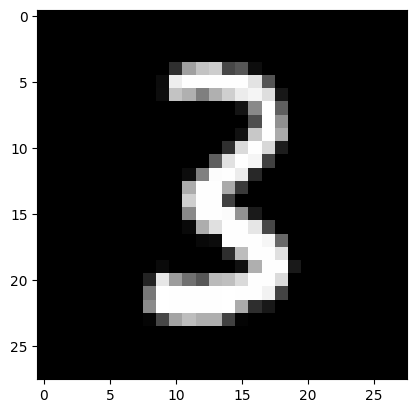

In [297]:
plt.imshow(xb[0].view(28,28))
yb[0].item()

In [298]:
model,opt = get_model()

In [299]:
# make a training function
def fit():
    for epoch in range(epochs):
        for xb,yb in train_dl:
            preds = model(xb)
            loss = loss_func(preds, yb)
            loss.backward()
            opt.step()
            opt.zero_grad()
        report(loss, preds, yb)

In [300]:
fit()

LOSS: 0.1553 | ACC: 96.00%
LOSS: 0.0646 | ACC: 98.00%
LOSS: 0.0558 | ACC: 100.00%


# Random sampling

- To make the training data random (we don't randomize the validation set)

In [301]:
import random

In [302]:
class Sampler():
    '''makes the indicies'''
    def __init__(self,ds,shuffle=False): self.n,self.shuffle = len(ds),shuffle
    def __iter__(self):
        idxs = list(range(self.n))
        if self.shuffle: random.shuffle(idxs)
        return iter(idxs)

In [303]:
from itertools import islice

In [304]:
ss = Sampler(train_ds)

In [305]:
it = iter(ss)
for o in range(5): print(next(it))

0
1
2
3
4


In [306]:
list(islice(ss, 6))

[0, 1, 2, 3, 4, 5]

In [307]:
# here we are using the shuffle
ss = Sampler(train_ds, shuffle=True)
list(islice(ss, 5))

[34408, 31378, 29316, 4506, 19904]

In [308]:
# that is just to store all attributes [self.STH = STH] , without us typing alot
import fastcore.all as fc

In [309]:
class BatchSampler():
    '''makes the indicies batchs'''
    def __init__(self,sampler,bs,drop_last=False): fc.store_attr()
    def __iter__(self): yield from fc.chunked(iter(self.sampler),
                                              self.bs,
                                              drop_last=self.drop_last)

- **valid_dl**          -> find the object
- **iter()**            -> create pointer, nothing run
- **next()**            -> run until yield, freeze
- **yield fires**       -> batch comes out
- **xb, yb =**         -> unpack it

**islice**

- no memory between calls
- loses position every time
- must load everything into a list to work properly
- list = everything in RAM at once

 **yield / generator**

- remembers position automatically
- one chunk at a time, rest never loaded
- tiny in RAM (just a pointer + chunk size)
- scales to any dataset size

 **iter / next / yield relationship**

- `iter()` — turns the machine on, nothing loaded yet
- `next()` — take one item off the belt
- `yield` — the pause point, fires when `next()` pulls the trigger

 **yield from vs yield**

- `yield` — hands back the whole container
- `yield from` — unwraps it, hands back each item inside one at a time

 **fc.chunked ()**
- takes an iterator and a chunk size, splits everything into groups
- lazy, one chunk at a time, nothing in RAM upfront
- `drop_last=True`  throws away the final chunk if smaller than bs
- needs iter() passed in so it can call next() internally

In [310]:
batchs = BatchSampler(ss,4)
list(islice(batchs,4))

[[37944, 18736, 14495, 24276],
 [47766, 25502, 5005, 27263],
 [36996, 27217, 3160, 21965],
 [16280, 24811, 29434, 49364]]

In [311]:
def collate(b):
    # b is a list of (image, label) tuples — one per sample in the batch:
    #   b = [(img0, lbl0), (img1, lbl1), (img2, lbl2), ...]
    #
    # zip(*b) "unzips" that:
    #   xs = (img0, img1, img2, ...)   <- all images
    #   ys = (lbl0, lbl1, lbl2, ...)   <- all labels
    #
    # torch.stack() takes a tuple of tensors and stacks them into ONE tensor:
    #   tensor([img0, img1, img2]) -> shape [batch_size, 784]
    xs, ys = zip(*b)
    return torch.stack(xs), torch.stack(ys)
    # Output: two tensors ready for the model

In [312]:
    class DataLoader():
        '''makes the dataloader'''
        def __init__(self,ds,batchs,collate_fn=collate):fc.store_attr()
        def __iter__(self): yield from (self.collate_fn(self.ds[i] for i in b) for b in self.batchs)

-   **self.batchs**  ->  [4,7,1,9]           chunk of indices
-   **self.ds[i]**   ->  (img,lbl) x4        raw data
-   **collate_fn**   ->  xb[4,784], yb[4]    stacked tensors
-   **yield from**   ->  hands to training loop

then,

-   training loop calls next() again
-   whole thing repeats for next chunk
-   previous batch thrown away from RAM

In [313]:
# let's use what we have made
train_samp = BatchSampler(Sampler(train_ds, shuffle=True ), bs)
valid_samp = BatchSampler(Sampler(valid_ds, shuffle=False), bs)

In [314]:
train_dl = DataLoader(train_ds, batchs=train_samp)
valid_dl = DataLoader(valid_ds, batchs=valid_samp)

In [315]:
xb,yb = next(iter(valid_dl))
xb.shape , yb.shape

(torch.Size([50, 784]), torch.Size([50]))

3

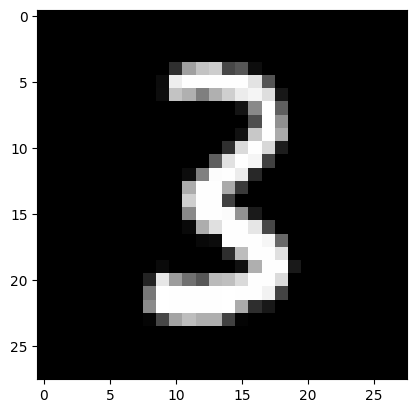

In [316]:
plt.imshow(xb[0].view(28,28))
yb[0].item()

In [317]:
model,opt = get_model()

In [318]:
fit()

LOSS: 0.1003 | ACC: 96.00%
LOSS: 0.2430 | ACC: 90.00%
LOSS: 0.1679 | ACC: 94.00%


# Multiprocessing DataLoader

In [319]:
import torch.multiprocessing as mp
from fastcore.basics import store_attr

In [320]:
train_ds[[3,6,8,1]]

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([1, 1, 1, 0]))

In [321]:
train_ds.__getitem__([3,6,8,1])

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([1, 1, 1, 0]))

In [322]:
for o in map(train_ds.__getitem__, ([3,6],[8,1])): print(o)

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]), tensor([1, 1]))
(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]), tensor([1, 0]))


In [323]:
# lets make a dataloader that makes the more loading of the data run in parallel
class DataLoader():
    def __init__(self,ds,batchs,n_workers=2,collate=collate):fc.store_attr() # collate function is not used here but we put it anyway
    def __iter__(self):
        with mp.Pool(self.n_workers) as ex : yield from ex.map(self.ds.__getitem__,iter(self.batchs))

In [324]:
train_dl = DataLoader(train_ds, batchs=train_samp, n_workers=1)
it = iter(train_dl)

In [325]:
# xb,yb = next(it)   ----> here it is just making some glitch with my jubiter and it is not running
# xb.shape,yb.shape

# Using the pytorch Dataloader

In [326]:
#|export
# imports
from torch.utils.data import DataLoader, SequentialSampler, RandomSampler, BatchSampler

In [327]:
train_samp = BatchSampler(RandomSampler(train_ds),     bs, drop_last=False)
valid_samp = BatchSampler(SequentialSampler(valid_ds), bs, drop_last=False)

In [328]:
train_dl = DataLoader(train_ds, batch_sampler=train_samp, collate_fn=collate) # there is a default collate function in pytorch (for knowledge)
valid_dl = DataLoader(valid_ds, batch_sampler=valid_samp, collate_fn=collate)

In [329]:
model,opt = get_model()
fit()

LOSS: 0.1086 | ACC: 98.00%
LOSS: 0.0341 | ACC: 100.00%
LOSS: 0.1622 | ACC: 96.00%


PyTorch can auto-generate the BatchSampler for us:

In [330]:
train_dl = DataLoader(train_ds, bs, sampler=RandomSampler(train_ds), collate_fn=collate)
valid_dl = DataLoader(valid_ds, bs, sampler=SequentialSampler(valid_ds), collate_fn=collate)

PyTorch can also generate the Sequential/RandomSamplers too:

In [331]:
train_dl = DataLoader(train_ds, bs, shuffle=True, drop_last=True, num_workers=2)
valid_dl = DataLoader(valid_ds, bs, shuffle=False, num_workers=2)

In [332]:
model,opt = get_model()
fit()

LOSS: 0.0701 | ACC: 98.00%
LOSS: 0.2191 | ACC: 92.00%
LOSS: 0.0266 | ACC: 100.00%


IDEA: Our dataset actually already knows how to sample a batch of indices all at once:

In [333]:
train_ds[[4,6,7]]

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([9, 1, 3]))

...that means that we can actually skip the  collate_fn entirely:

In [334]:
train_dl = DataLoader(train_ds, sampler=train_samp)
valid_dl = DataLoader(valid_ds, sampler=valid_samp)

In [335]:
xb,yb = next(iter(train_dl))
xb.shape,yb.shape

(torch.Size([1, 50, 784]), torch.Size([1, 50]))

# Making a full training loop with the validation report

`mode.train()`

1. **DROPOUT:**


        training mode:    randomly zeros out neurons (prevents overfitting)
        eval mode:        no dropout, all neurons active
                           (you want full model power when predicting)

2. **BATCHNORM:**


        training mode:    uses statistics from CURRENT batch
        eval mode:        uses statistics accumulated during training
                              (current batch might be too small to trust)

 AND `model.eval()` IS THE REVERSE

In [336]:
def accuracy(preds, y):
    return (preds.argmax(dim=1) == y).float().mean()

In [337]:
#|export
def fit(epochs,model,loss_fn,opt,train_dl,valid_dl):
    for epoch in range(epochs):
        ## Train
        model.train()
        for x,y in train_dl:
            preds = model(x)
            loss = loss_fn(preds, y)
            loss.backward()
            opt.step()
            opt.zero_grad()
        ## Inference
        model.eval()
        with torch.no_grad():
            tot_loss,tot_acc,count = 0.,0.,0
            for x,y in valid_dl:
                preds = model(x)
                n = len(x)  ## That n thing is just to handle if there was smaller batch at the end --> technically a mean
                count += n
                tot_loss += loss_fn(preds,y).item()*n
                tot_acc  += accuracy(preds,y).item()*n
        print(f"EPOCH: {epoch} | LOSS: {tot_loss / count:.3f} | ACC: {(tot_acc / count)*100:.3f}")
    return tot_loss/count, tot_acc/count

Why n:
 
- batch1: loss=0.3, n=64  -> 0.3*64 = 19.2
-   batch2: loss=0.4, n=37  -> 0.4*37 = 14.8
-   total: (19.2+14.8) / (64+37) = 34/101 = 0.336  <- correct average

In [338]:
#|export
def get_dls(train_ds, valid_ds, bs, **kwargs):
    return (DataLoader(train_ds, batch_size=bs, shuffle=True, **kwargs),
            DataLoader(valid_ds, batch_size=bs*2, **kwargs))

In [339]:
train_dl,valid_dl = get_dls(train_ds, valid_ds, bs)
model,opt = get_model()

In [340]:
%time loss,acc = fit(5, model, loss_func, opt, train_dl, valid_dl)

EPOCH: 0 | LOSS: 0.155 | ACC: 95.380
EPOCH: 1 | LOSS: 0.126 | ACC: 96.270
EPOCH: 2 | LOSS: 0.117 | ACC: 96.580
EPOCH: 3 | LOSS: 0.107 | ACC: 96.890
EPOCH: 4 | LOSS: 0.102 | ACC: 97.130
CPU times: user 22.6 s, sys: 32.8 ms, total: 22.7 s
Wall time: 2.83 s


# Export

In [341]:
# import nbdev; nbdev.nbdev_export()

Exception: `nbdev-export` must be called from a directory within a nbdev project.